# 13 — XJTU-SY: Closing the Per-Unit Calibration Loop

Notebook 08 asked what a per-unit healthy baseline is worth and could only
answer half the question. Paderborn records each bearing at **one** health
state, so it can measure how often a baseline false-alarms on a healthy unit,
but it cannot measure whether that baseline would have *caught* the fault, or
how early. Notebook 08 concluded, from a variance decomposition, that
calibration is "a false-alarm fix, not a sensitivity fix" — a reasonable
inference that had no way to be tested.

XJTU-SY was chosen to test it. Fifteen bearings run from new to failure with
one 1.28 s snapshot per minute, so every unit is its own healthy baseline
*and* its own fault case. The full arc is visible: 42 minutes for the shortest
life, 2538 for the longest.

Three questions, in order:

1. **Does the notebook 06–11 envelope pipeline transfer to a different rig?**
   Different bearing (LDK UER204, BPFO 3.083·fr against Paderborn's 3.071),
   different speeds, different sampling rate.
2. **How badly does a foreign healthy baseline fail here?** Notebook 07 found a
   single-unit baseline can be 100 % wrong on another healthy unit, on six
   units. Fifteen gives 210 ordered pairs.
3. **What does per-unit calibration actually buy** — false alarms only, as
   notebook 08 concluded, or detection too?

One assumption is load-bearing throughout and is stated here rather than
buried: **the early life of each bearing is healthy.** These are new bearings
in an accelerated test run until vibration exceeds 10× its normal-stage
amplitude, so the first minutes are healthy by construction. Where a "false
alarm" is measured below, it is measured over the first 10 % of a unit's life,
and only on the five units that live 400 minutes or more, so that window is
never a handful of snapshots.

In [1]:
import pathlib
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import butter, sosfiltfilt, hilbert, get_window
from scipy.stats import kurtosis

RAW = pathlib.Path("../data/raw/xjtu")
OUT = pathlib.Path("../data/processed")
COND = {"35Hz12kN": 35.0, "37.5Hz11kN": 37.5, "40Hz10kN": 40.0}

FS, WIN = 25_600, 32_768                 # one whole snapshot -> 0.781 Hz bins
HANN = get_window("hann", WIN)
F = np.fft.rfftfreq(WIN, 1 / FS)
FLOOR = (F > 10) & (F < 400)
# Nyquist is 12.8 kHz here against Paderborn's 32 kHz, so the resonance band
# stops at 12 kHz rather than notebooks 06-11's 20 kHz. Same intent.
SOS = butter(4, (1000, 12000), btype="bandpass", fs=FS, output="sos")

N_BALLS, BD, PD = 8, 7.92, 34.55         # LDK UER204
O_BPFO = N_BALLS / 2 * (1 - BD / PD)     # 3.0831  (Paderborn 6203: 3.0706)
O_BPFI = N_BALLS / 2 * (1 + BD / PD)     # 4.9169  (Paderborn 6203: 4.9294)
O_BSF = PD / (2 * BD) * (1 - (BD / PD) ** 2)
O_FTF = 0.5 * (1 - BD / PD)
HALF = 3.0                               # Hz half-width, ~4 bins

# Fault element per bearing, from Table 2 of the introduction PDF the archive
# ships. Lifetimes in that table were checked against the extracted file counts.
FAULT = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR",
         "Bearing1_4": "cage", "Bearing1_5": "IR+OR", "Bearing2_1": "IR",
         "Bearing2_2": "OR", "Bearing2_3": "cage", "Bearing2_4": "OR",
         "Bearing2_5": "OR", "Bearing3_1": "OR", "Bearing3_2": "compound",
         "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}


def peak_db(spec, hz, floor):
    m = (F >= hz - HALF) & (F <= hz + HALF)
    return 10 * np.log10(spec[m].max() / floor)


def snapshot_row(x, fr, tag):
    e = np.abs(hilbert(sosfiltfilt(SOS, x)))
    spec = np.abs(np.fft.rfft((e - e.mean()) * HANN)) ** 2
    fl = np.median(spec[FLOOR])
    bpfo, bpfi = O_BPFO * fr, O_BPFI * fr
    g = lambda hz: peak_db(spec, hz, fl)
    return {f"{tag}_RMS": float(np.sqrt(np.mean(x ** 2))),
            f"{tag}_Kurt": float(kurtosis(x, fisher=True)),
            f"{tag}_BPFO": g(bpfo), f"{tag}_BPFI": g(bpfi), f"{tag}_FR": g(fr),
            f"{tag}_BPFO_h2": g(2 * bpfo), f"{tag}_BPFI_h2": g(2 * bpfi),
            f"{tag}_BSF": g(O_BSF * fr), f"{tag}_FTF": g(O_FTF * fr),
            f"{tag}_BPFI_sb1": 0.5 * (g(bpfi - fr) + g(bpfi + fr)),
            f"{tag}_BPFO_sb1": 0.5 * (g(bpfo - fr) + g(bpfo + fr))}


def build():
    """9216 snapshots, ~7 min. Cached, as in notebook 11."""
    path = OUT / "xjtu_envelope_features.csv"
    if path.exists():
        return pd.read_csv(path)
    rows = []
    for cond, fr in COND.items():
        for bdir in sorted((RAW / cond).iterdir(), key=lambda p: p.name):
            for f in sorted(bdir.glob("*.csv"), key=lambda p: int(p.stem)):
                x = pd.read_csv(f).to_numpy(dtype=np.float64)
                r = {"Cond": cond, "Bearing": bdir.name, "Snapshot": int(f.stem), "fr_Hz": fr}
                r.update(snapshot_row(x[:, 0], fr, "H"))
                r.update(snapshot_row(x[:, 1], fr, "V"))
                rows.append(r)
    d = pd.DataFrame(rows)
    d.to_csv(path, index=False)
    return d


t0 = time.time()
ds = build()
BEAR = sorted(ds["Bearing"].unique())
CONDOF = ds.drop_duplicates("Bearing").set_index("Bearing")["Cond"]
G = {b: ds[ds["Bearing"] == b].sort_values("Snapshot") for b in BEAR}
N = {b: len(G[b]) for b in BEAR}
LONG = [b for b in BEAR if N[b] >= 400]          # units with a wide healthy window

ORD = ["H_BPFO", "H_BPFI", "H_FR", "H_BPFO_h2", "H_BPFI_h2", "H_BSF", "H_FTF"]
SETS = {"order bands": ORD,
        "order + sidebands": ORD + ["H_BPFI_sb1", "H_BPFO_sb1"],
        "RMS only": ["H_RMS"],
        "RMS + kurtosis": ["H_RMS", "H_Kurt"]}

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE, "cage": "#7a9e3f",
          "IR+OR": "#8f6bb5", "compound": MUTED}
HEAT = LinearSegmentedColormap.from_list("heat", [SURFACE, "#f6d3c2", C_ORANGE, "#8c3311"])
DIV = LinearSegmentedColormap.from_list("div", [C_BLUE, "#cfd8e6", SURFACE, "#f6d3c2", C_ORANGE])

print(f"{len(ds)} snapshots over {len(BEAR)} bearings, "
      f"{N[min(N, key=N.get)]}-{N[max(N, key=N.get)]} min lifetimes  ({time.time() - t0:.0f}s)")
print(f"BPFO={O_BPFO:.4f} fr, BPFI={O_BPFI:.4f} fr | bin width {F[1]:.3f} Hz")

9216 snapshots over 15 bearings, 42-2538 min lifetimes  (0s)
BPFO=3.0831 fr, BPFI=4.9169 fr | bin width 0.781 Hz


## Does the pipeline transfer to a different rig?

Before any calibration question, the features have to work at all. The test is
the one notebooks 10 and 11 set up: an **outer-race** defect should raise BPFO,
and an **inner-race** defect should raise **shaft rate**, because an inner-race
defect passes through the load zone once per revolution and an outer-race
defect sits in it.

Nothing here is fitted. It is the change in each feature from a unit's first
ten snapshots to its last ten, against the fault element the dataset documents.

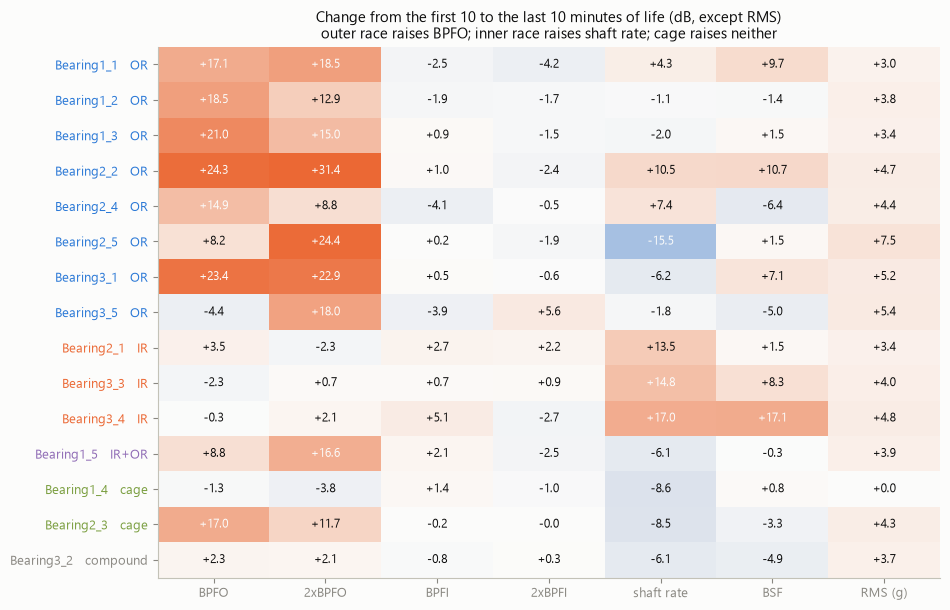

,H_BPFO,H_BPFO_h2,H_BPFI,H_BPFI_h2,H_FR,H_BSF,H_RMS
Bearing1_1,17.1,18.5,-2.5,-4.2,4.3,9.7,3.0
Bearing1_2,18.5,12.9,-1.9,-1.7,-1.1,-1.4,3.8
Bearing1_3,21.0,15.0,0.9,-1.5,-2.0,1.5,3.4
Bearing2_2,24.3,31.4,1.0,-2.4,10.5,10.7,4.7
Bearing2_4,14.9,8.8,-4.1,-0.5,7.4,-6.4,4.4
Bearing2_5,8.2,24.4,0.2,-1.9,-15.5,1.5,7.5
Bearing3_1,23.4,22.9,0.5,-0.6,-6.2,7.1,5.2
Bearing3_5,-4.4,18.0,-3.9,5.6,-1.8,-5.0,5.4
Bearing2_1,3.5,-2.3,2.7,2.2,13.5,1.5,3.4
Bearing3_3,-2.3,0.7,0.7,0.9,14.8,8.3,4.0


In [2]:
SHOW = ["H_BPFO", "H_BPFO_h2", "H_BPFI", "H_BPFI_h2", "H_FR", "H_BSF", "H_RMS"]
NICE = ["BPFO", "2xBPFO", "BPFI", "2xBPFI", "shaft rate", "BSF", "RMS (g)"]
ORDER = sorted(BEAR, key=lambda b: (FAULT[b] != "OR", FAULT[b], b))

chg = pd.DataFrame({f: {b: G[b][f].tail(10).median() - G[b][f].head(10).median()
                        for b in ORDER} for f in SHOW}).loc[ORDER]

fig, ax = plt.subplots(figsize=(9.6, 6.2))
ax.imshow(chg.to_numpy(), cmap=DIV, vmin=-25, vmax=25, aspect="auto")
for i in range(chg.shape[0]):
    for j in range(chg.shape[1]):
        v = chg.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8.5,
                color=SURFACE if abs(v) > 14 else INK)
ax.set_xticks(range(len(SHOW)), NICE, fontsize=9.5)
ax.set_yticks(range(len(ORDER)),
              [f"{b}   {FAULT[b]}" for b in ORDER], fontsize=9)
for i, b in enumerate(ORDER):
    ax.get_yticklabels()[i].set_color(FCOLOR[FAULT[b]])
ax.grid(visible=False)
ax.set_title("Change from the first 10 to the last 10 minutes of life (dB, except RMS)\n"
             "outer race raises BPFO; inner race raises shaft rate; cage raises neither",
             fontsize=11)
plt.tight_layout()
plt.show()

chg.round(1)

**The pipeline transfers, and the load-zone argument holds on a second rig.**

Every one of the eight outer-race bearings raises **BPFO** — by 8 to 24 dB —
and its second harmonic with it. Not one inner-race bearing does. The three
inner-race units instead raise **shaft rate** by 13 to 17 dB, which is exactly
the mechanism notebook 10 inferred from Paderborn's low-load result and
notebook 11 built the sideband features on. Two rigs, two bearing geometries,
same physics.

Two exceptions are worth naming rather than smoothing over. **Bearing3_5** is
an outer-race failure whose BPFO *falls* 4.4 dB while its second harmonic rises
18.0 dB — the fault energy is there but lands on 2×BPFO. And **Bearing1_4**, a
cage failure, moves almost nothing: BPFO −1.3 dB, and an RMS change of 0.05
against 3–7 for every other unit. Cage failure is a mode Paderborn does not
contain at all, and it is nearly invisible to bearing-frequency features.

## How badly does a foreign healthy baseline fail?

Notebook 07's cross-baseline matrix, now with fifteen units instead of six.
Each row is a baseline fitted on one unit's first ten healthy minutes, with its
threshold at its own 99th percentile; each column is the alarm rate that
baseline produces on **another unit's healthy first ten minutes**. Every cell
off the diagonal is a false alarm by construction — both units are healthy.

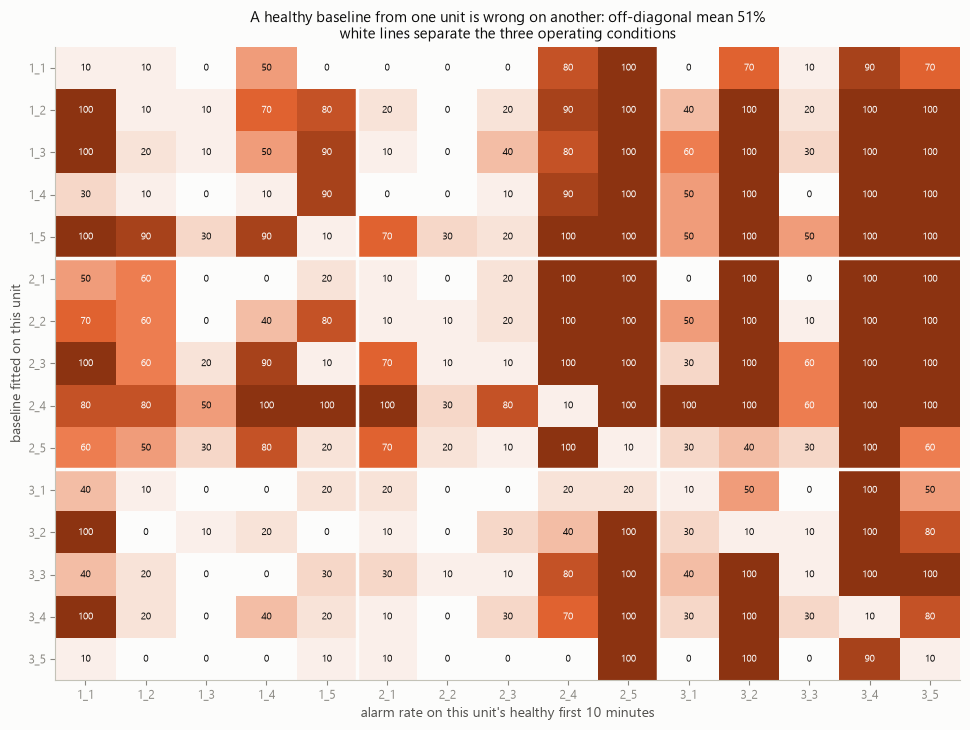

off-diagonal: mean 51.0%, median 50%, 29% of the 210 pairs alarm on 100% of healthy snapshots
same operating condition 57.5%  |  different 48.4%


In [3]:
H = 10                       # healthy reference: first 10 minutes of a new bearing


class Exceedance:
    """Robust per-feature z over a healthy baseline, max-pooled (notebook 07)."""

    def fit(self, A):
        self.med = np.median(A, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(A - self.med), axis=0), 0.1)
        return self

    def score(self, A):
        return ((A - self.med) / self.mad).max(axis=1)


X = {b: G[b][ORD].to_numpy() for b in BEAR}
cross = pd.DataFrame(index=BEAR, columns=BEAR, dtype=float)
for a in BEAR:
    m = Exceedance().fit(X[a][:H])
    thr = np.quantile(m.score(X[a][:H]), 0.99)
    for b in BEAR:
        cross.loc[a, b] = (m.score(X[b][:H]) > thr).mean()

off = cross.to_numpy()[~np.eye(len(BEAR), dtype=bool)]
same = [cross.loc[a, b] for a in BEAR for b in BEAR
        if a != b and CONDOF[a] == CONDOF[b]]
diff = [cross.loc[a, b] for a in BEAR for b in BEAR
        if a != b and CONDOF[a] != CONDOF[b]]

fig, ax = plt.subplots(figsize=(9.8, 7.4))
ax.imshow(cross.to_numpy(), cmap=HEAT, vmin=0, vmax=1, aspect="auto")
for i in range(15):
    for j in range(15):
        v = cross.iat[i, j]
        ax.text(j, i, f"{v:.0%}"[:-1], ha="center", va="center", fontsize=7.5,
                color=SURFACE if v > 0.55 else INK)
short = [b.replace("Bearing", "") for b in BEAR]
ax.set_xticks(range(15), short, fontsize=8.5)
ax.set_yticks(range(15), short, fontsize=8.5)
for k in (4.5, 9.5):
    ax.axvline(k, color=SURFACE, lw=2.5)
    ax.axhline(k, color=SURFACE, lw=2.5)
ax.set_xlabel("alarm rate on this unit's healthy first 10 minutes")
ax.set_ylabel("baseline fitted on this unit")
ax.grid(visible=False)
ax.set_title(f"A healthy baseline from one unit is wrong on another: "
             f"off-diagonal mean {off.mean():.0%}\n"
             f"white lines separate the three operating conditions", fontsize=11)
plt.tight_layout()
plt.show()

print(f"off-diagonal: mean {off.mean():.1%}, median {np.median(off):.0%}, "
      f"{np.mean(off == 1):.0%} of the 210 pairs alarm on 100% of healthy snapshots")
print(f"same operating condition {np.mean(same):.1%}  |  different {np.mean(diff):.1%}")

**The result is much stronger than notebook 07's, and it points somewhere
different.** A baseline built on one healthy unit alarms on **51 %** of another
healthy unit's snapshots on average. In 28 % of the 210 ordered pairs it alarms
on *everything*. Notebook 07 called a 100 % cross-unit failure the worst case
on six Paderborn bearings; on fifteen XJTU units it is the single most common
outcome.

The direction of the operating-condition effect is the surprise.
Notebook 08 found a Paderborn baseline was **speed-specific** — a 1500 rpm
baseline false-alarmed on 99.8 % of 900 rpm healthy windows — which suggested
the operating point was the thing that broke transfer. Here baselines transfer
*slightly worse* **within** the same speed and load (57.5 %) than **across**
different ones (48.4 %). Operating condition explains none of it. What is left
is unit-to-unit variation: how this particular bearing sits in this particular
housing.

That is the same installation-signature effect notebook 07 found in Paderborn's
healthy population, and on this rig it is large enough to swamp a 5 Hz speed
change and a 2 kN load change.

## What does per-unit calibration buy?

Now the question notebook 08 could not reach. Two baselines, both scored on the
same unit-under-test:

- **own-unit** — fitted on that unit's own first 20 minutes;
- **foreign** — fitted on the other fourteen units' healthy first 10 minutes,
  pooled, which is the best a fleet baseline can do without touching the unit.

An alarm is called when **the majority of the trailing 10 snapshots exceed the
threshold**, rather than on a plainer three-consecutive-exceedances rule, which
an intermittent unit satisfies by chance.

The rule change is not enough on its own, and the reason is worth stating up
front. **Bearing3_2 alarms at minute 34 of a 2496-minute life under either
rule** — a 99 % lead that is not a detection. Its own first twenty minutes
happen to be unusually quiet, so its threshold is set too tight for its own
later healthy behaviour, and 20 % of its first tenth of life exceeds it. That
is a false alarm, and it is the reason false alarms below are measured over the
whole first 10 % of life rather than a short window just after calibration: a
narrow window scores Bearing3_2 at 0 % and hides the problem entirely. Per-unit
calibration has a failure mode, and this is it.

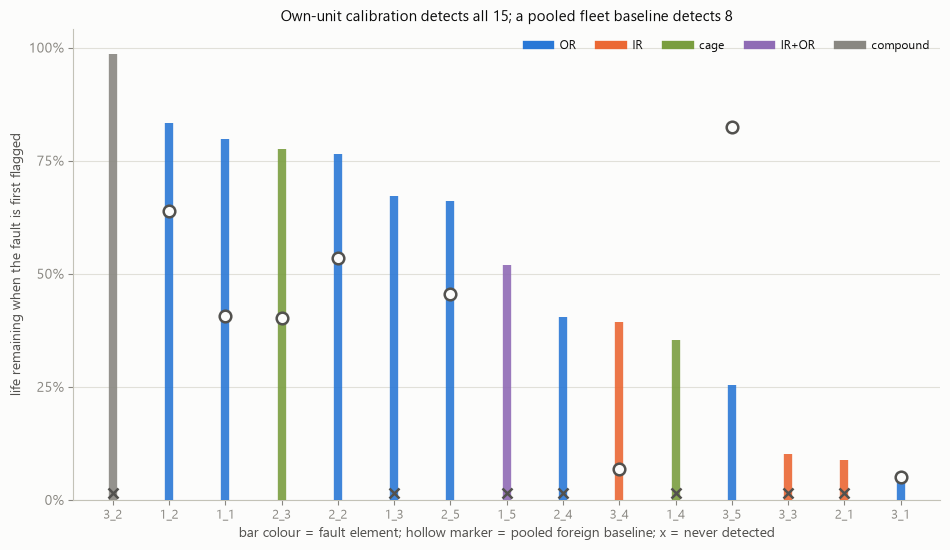

own-unit : 15/15 detected, median lead 51.9% of life
foreign  : 8/15 detected, median lead 43.0% of life
wrote xjtu_detection_own_vs_pooled.csv


In [4]:
K, W = 20, 10        # calibration minutes; trailing window for the alarm rule


def sustained(flags, offset):
    """First index where a majority of the trailing W snapshots exceed."""
    if len(flags) < W:
        return None
    c = np.convolve(flags.astype(float), np.ones(W) / W, mode="valid")
    hit = np.flatnonzero(c >= 0.5)
    return None if hit.size == 0 else int(hit[0]) + offset


def baselines(b, feats=ORD, k=K):
    """(own-unit model, threshold), (pooled-foreign model, threshold)."""
    Xb = G[b][feats].to_numpy()
    mo = Exceedance().fit(Xb[:k])
    to = np.quantile(mo.score(Xb[:k]), 0.99)
    pool = np.vstack([G[o][feats].to_numpy()[:H] for o in BEAR if o != b])
    mf = Exceedance().fit(pool)
    tf = np.quantile(mf.score(pool), 0.99)
    return Xb, (mo, to), (mf, tf)


rows = []
for b in BEAR:
    Xb, (mo, to), (mf, tf) = baselines(b)
    ao = sustained(mo.score(Xb)[K:] > to, K)
    af = sustained(mf.score(Xb)[K:] > tf, K)
    rows.append(dict(Bearing=b, fault=FAULT[b], N=N[b],
                     own=None if ao is None else (N[b] - ao) / N[b],
                     foreign=None if af is None else (N[b] - af) / N[b]))
cmp = pd.DataFrame(rows).set_index("Bearing")

fig, ax = plt.subplots(figsize=(9.6, 5.6))
xs = np.arange(len(BEAR))
order = sorted(BEAR, key=lambda b: -(cmp.loc[b, "own"] or 0))
for i, b in enumerate(order):
    o, f = cmp.loc[b, "own"], cmp.loc[b, "foreign"]
    c = FCOLOR[FAULT[b]]
    ax.plot([i, i], [0, o], color=c, lw=6, alpha=0.9, solid_capstyle="butt", zorder=3)
    if pd.notna(f):
        ax.scatter([i], [f], s=70, facecolors=SURFACE, edgecolors=INK2,
                   linewidths=1.8, zorder=5)
    else:
        ax.scatter([i], [0.015], s=52, marker="x", color=INK2, linewidths=1.8, zorder=5)
ax.set_xticks(xs, [b.replace("Bearing", "") for b in order], fontsize=9)
ax.set_ylim(0, 1.04)
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_ylabel("life remaining when the fault is first flagged")
ax.set_xlabel("bar colour = fault element; hollow marker = pooled foreign baseline; x = never detected")
ax.grid(axis="x", visible=False)
ax.set_title(f"Own-unit calibration detects all 15; a pooled fleet baseline detects "
             f"{int(cmp['foreign'].notna().sum())}", fontsize=11)
handles = [plt.Line2D([], [], color=v, lw=6, label=k) for k, v in FCOLOR.items()]
ax.legend(handles=handles, fontsize=8.5, ncol=5, loc="upper right")
plt.tight_layout()
plt.show()

print(f"own-unit : {int(cmp['own'].notna().sum())}/15 detected, "
      f"median lead {cmp['own'].median():.1%} of life")
print(f"foreign  : {int(cmp['foreign'].notna().sum())}/15 detected, "
      f"median lead {cmp['foreign'].median():.1%} of life")
cmp.style.format({"own": "{:.1%}", "foreign": "{:.1%}"}, na_rep="never")
# Cached so build_registry.py can recompute the 15-of-15 claim
cmp.to_csv(OUT / "xjtu_detection_own_vs_pooled.csv")
print("wrote xjtu_detection_own_vs_pooled.csv")


**Notebook 08's conclusion was wrong, and it was wrong in the direction its own
method could not see.** Per-unit calibration is not only a false-alarm fix. The
own-unit baseline flags every one of the fifteen bearings; the pooled fleet
baseline flags **eight**, and misses both pure inner-race units outright.

The mechanism is visible in the width of the healthy reference. Pooling
fourteen units does not just shift the median — it inflates the MAD, because
unit-to-unit spread is now inside the estimate of "normal". A wider reference
is a blunter instrument: it false-alarms less (0 % on healthy units here, against
51 % for a single foreign unit) and detects less. Notebook 08 measured the first
half of that trade and inferred the second half backwards.

One unit runs the other way and is worth naming: the pooled baseline flags
**Bearing3_5** with 82 % of life left against the own-unit baseline's 25 %. It
is not a better detection. That same pooled baseline alarms on **40 % of
Bearing3_5's healthy first ten minutes** — the only unit where it does — so it
was already alarming before anything went wrong.

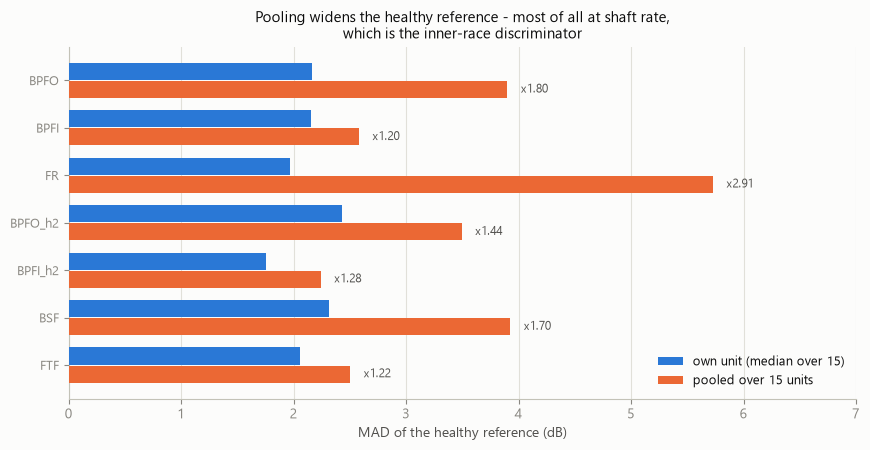

,own unit (median),pooled over 15,widening
BPFO,2.16,3.90,1.80
BPFI,2.15,2.58,1.20
FR,1.97,5.73,2.91
BPFO_h2,2.43,3.49,1.44
BPFI_h2,1.75,2.24,1.28
BSF,2.32,3.93,1.70
FTF,2.06,2.50,1.22


In [5]:
own_mad = np.array([np.maximum(1.4826 * np.median(
    np.abs(G[b][ORD].to_numpy()[:H] - np.median(G[b][ORD].to_numpy()[:H], axis=0)),
    axis=0), 0.1) for b in BEAR])
pool = np.vstack([G[b][ORD].to_numpy()[:H] for b in BEAR])
pool_mad = np.maximum(1.4826 * np.median(np.abs(pool - np.median(pool, axis=0)), axis=0), 0.1)
wid = pd.DataFrame({"own unit (median)": np.median(own_mad, axis=0),
                    "pooled over 15": pool_mad},
                   index=[c.replace("H_", "") for c in ORD])
wid["widening"] = wid["pooled over 15"] / wid["own unit (median)"]

fig, ax = plt.subplots(figsize=(8.8, 4.6))
y = np.arange(len(wid))
ax.barh(y - 0.19, wid["own unit (median)"], height=0.36, color=C_BLUE, zorder=3,
        label="own unit (median over 15)")
ax.barh(y + 0.19, wid["pooled over 15"], height=0.36, color=C_ORANGE, zorder=3,
        label="pooled over 15 units")
for i, v in enumerate(wid["widening"]):
    ax.text(wid["pooled over 15"].iloc[i] + 0.12, i + 0.19, f"x{v:.2f}",
            va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, wid.index, fontsize=9.5)
ax.invert_yaxis()
ax.set_xlabel("MAD of the healthy reference (dB)")
ax.set_xlim(0, 7)
ax.grid(axis="y", visible=False)
ax.legend(fontsize=9, loc="lower right")
ax.set_title("Pooling widens the healthy reference - most of all at shaft rate,\n"
             "which is the inner-race discriminator", fontsize=11)
plt.tight_layout()
plt.show()

wid.round(2)

**Shaft rate widens by 2.9×** — far more than any other feature, and more than
twice the median widening of 1.44×. That is precisely the feature that carries
inner-race damage, as the first figure showed. Pooling therefore does not blunt
the instrument evenly: it blunts it hardest exactly where inner-race faults
live, which is why the pooled baseline misses Bearing2_1 and Bearing3_3
completely and catches Bearing3_4 with 7 % of its life left instead of 39 %.

A fleet baseline is not a weaker version of a per-unit baseline. It is
selectively deaf to the fault type whose signature varies most between
installations.

## The calibration budget, now with a sensitivity axis

Notebook 08's headline was a budget: **≈ 38 s** of own-unit healthy data
(10 records) bought false alarms of 1.2 %. It could not price what that costs,
because Paderborn has no fault to be late for. Here both axes are measurable, so
the budget becomes a curve rather than a number — more own-unit data gives a
tighter, better-estimated threshold, which means fewer false alarms and a later
alarm.

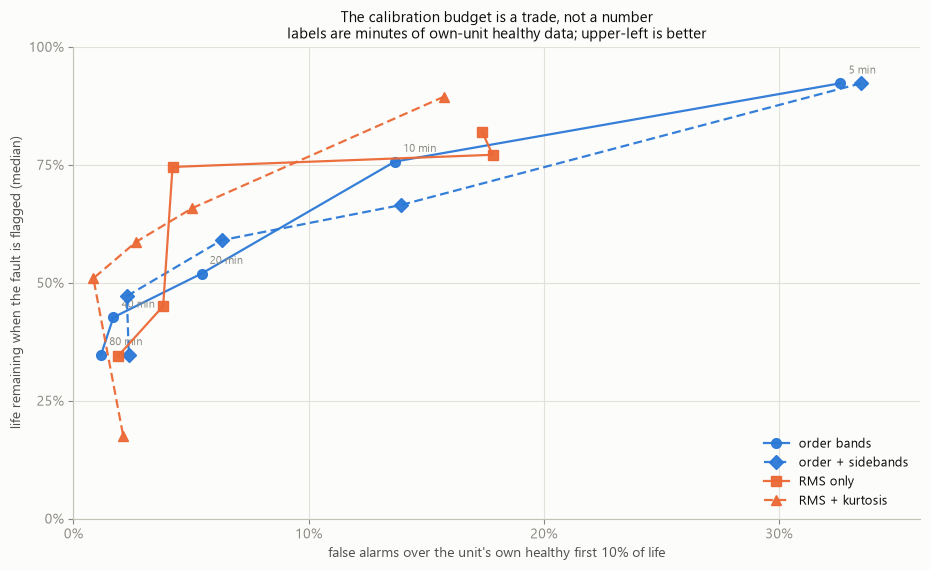

lead                                                    fa  \
features RMS + kurtosis RMS only order + sidebands order bands RMS + kurtosis   
K                                                                               
5                 0.894    0.820             0.923       0.923          0.158   
10                0.658    0.771             0.665       0.757          0.051   
20                0.587    0.745             0.590       0.519          0.027   
40                0.509    0.450             0.472       0.427          0.009   
80                0.175    0.344             0.347       0.347          0.021   

                                                 
features RMS only order + sidebands order bands  
K                                                
5           0.174             0.335       0.326  
10          0.178             0.139       0.137  
20          0.042             0.063       0.054  
40          0.038             0.023       0.017  
80          0.019             0.024       0.012

In [6]:
def measure(feats, k):
    """(detected, median life-remaining at alarm, false alarm) for a calibration
    budget of k minutes. False alarms are counted over the rest of the first 10%
    of life, on the five units that live 400+ minutes."""
    leads, fas, det = [], [], 0
    for b in BEAR:
        Xb = G[b][feats].to_numpy()
        m = Exceedance().fit(Xb[:k])
        thr = np.quantile(m.score(Xb[:k]), 0.99)
        s = m.score(Xb)
        a = sustained(s[k:] > thr, k)
        if a is not None:
            det += 1
            leads.append((N[b] - a) / N[b])
        if b in LONG:
            fas.append((s[k:max(k + W, N[b] // 10)] > thr).mean())
    return det, (np.median(leads) if leads else np.nan), float(np.mean(fas))


BUDGET = [5, 10, 20, 40, 80]
curve = pd.DataFrame([dict(features=name, K=k, minutes=k, seconds=k * 1.28,
                           detected=d, lead=l, fa=f)
                      for name, feats in SETS.items()
                      for k, (d, l, f) in ((k, measure(feats, k)) for k in BUDGET)])

fig, ax = plt.subplots(figsize=(9.4, 5.8))
STYLE = {"order bands": (C_BLUE, "o", "-"), "order + sidebands": (C_BLUE, "D", (0, (4, 2))),
         "RMS only": (C_ORANGE, "s", "-"), "RMS + kurtosis": (C_ORANGE, "^", (0, (4, 2)))}
for name, (c, mk, ls) in STYLE.items():
    s = curve[curve["features"] == name]
    ax.plot(s["fa"], s["lead"], color=c, ls=ls, lw=1.6, marker=mk, ms=7,
            alpha=0.95, label=name, zorder=3)
    for _, r in s.iterrows():
        if name == "order bands":
            ax.annotate(f"{int(r['K'])} min", (r["fa"], r["lead"]),
                        textcoords="offset points", xytext=(6, 7),
                        fontsize=8, color=MUTED)
ax.set_xlabel("false alarms over the unit's own healthy first 10% of life")
ax.set_ylabel("life remaining when the fault is flagged (median)")
ax.set_xlim(0, 0.36)
ax.set_ylim(0, 1.0)
ax.set_xticks([0, .1, .2, .3], ["0%", "10%", "20%", "30%"])
ax.set_yticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.legend(fontsize=9, loc="lower right")
ax.set_title("The calibration budget is a trade, not a number\n"
             "labels are minutes of own-unit healthy data; upper-left is better",
             fontsize=11)
plt.tight_layout()
plt.show()

curve.pivot(index="K", columns="features", values=["lead", "fa"]).round(3)

Two things fall out, and the second is uncomfortable for the project's own
feature work.

**Notebook 08's budget replicates on an independent rig.** Reaching roughly
1 % false alarms takes 40–80 minutes of own-unit healthy monitoring, which at
1.28 s per snapshot is **51–102 s of signal** against notebook 08's ≈ 38 s.
Same order of magnitude, on a different bearing, rig and fault population. That
number is now worth quoting as a design figure rather than a Paderborn
artefact — but it should be quoted with its cost: buying that 1 % means
flagging the fault with about **35 % of life left instead of 75 %**.

**Plain RMS beats the envelope order bands for detection, on both axes.** At a
20-minute budget, RMS alone flags every bearing with **74.5 %** of life
remaining at **4.2 %** false alarms, where the seven physics-anchored order
bands manage 51.9 % at 5.4 %. Adding kurtosis trades lead for quiet: 58.7 % at
2.7 %.

That is not a contradiction of notebook 07, which compared three envelope
fundamentals against 59 envelope order bands and never tested a time-domain
indicator — but it is a real correction to an assumption this project has
carried since notebook 03. The envelope features earn their place at
**attribution**: BPFO and shaft rate are what say *which* race, as the first
figure shows and notebooks 11 and 12 built on. For the simpler question of
*whether* something is wrong, a broadband energy measure is both earlier and
quieter. The project's own "detectable is not attributable" distinction cuts in
this direction too, and it was not being applied to feature choice.

**Notebook 12's sideband gain does not transfer.** On Paderborn, adding
sidebands to the anomaly channel cut false alarms from 10.0 % to 6.7 %. Here it
changes nothing: 5.4 % becomes 6.3 % at a 20-minute budget, 13.7 % becomes
13.9 % at ten. Notebook 12 warned this might happen — it found `BPFO_sb1`
sitting on the Paderborn rig's own harmonic family, carrying a 21 dB healthy
pedestal, and concluded part of the gain was rig contamination rather than
bearing physics. A different rig has a different harmonic family, and the
benefit vanishes. **The caveat was right, and this is the confirmation.**

## Which faults are caught late

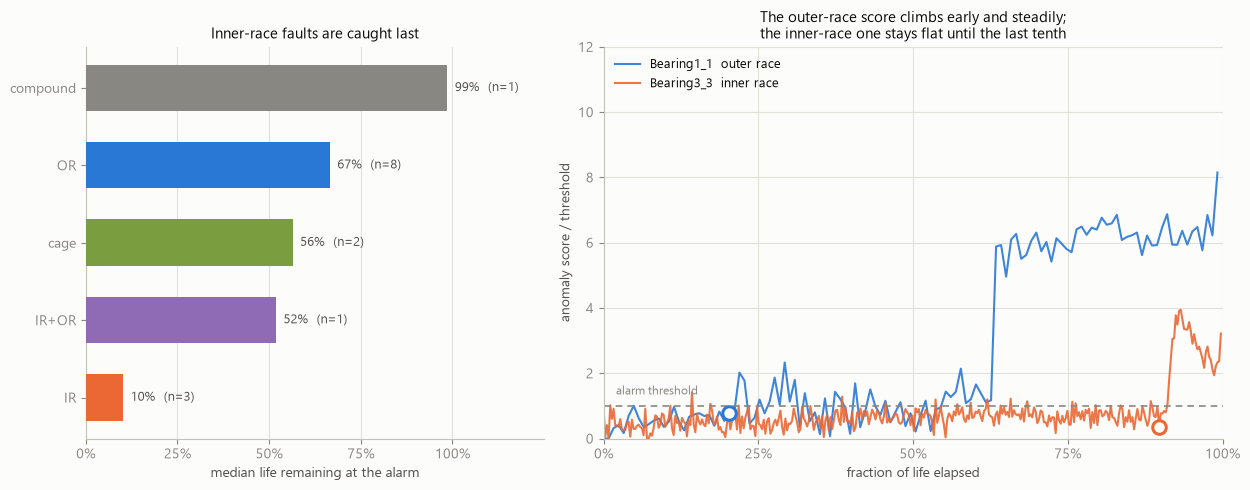

,fault,N,alarm,lead
Bearing,,,,
Bearing1_1,OR,123,25,79.7%
Bearing1_2,OR,161,27,83.2%
Bearing1_3,OR,158,52,67.1%
Bearing1_4,cage,122,79,35.2%
Bearing1_5,IR+OR,52,25,51.9%
Bearing2_1,IR,491,448,8.8%
Bearing2_2,OR,161,38,76.4%
Bearing2_3,cage,533,119,77.7%
Bearing2_4,OR,42,25,40.5%


In [7]:
det = []
for b in BEAR:
    Xb = G[b][ORD].to_numpy()
    m = Exceedance().fit(Xb[:K])
    thr = np.quantile(m.score(Xb[:K]), 0.99)
    a = sustained(m.score(Xb)[K:] > thr, K)
    det.append(dict(Bearing=b, fault=FAULT[b], N=N[b], alarm=a,
                    lead=None if a is None else (N[b] - a) / N[b]))
det = pd.DataFrame(det).set_index("Bearing")
by_fault = det.groupby("fault")["lead"].agg(["median", "count"]).sort_values("median")

fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.0),
                         gridspec_kw={"width_ratios": [1, 1.35]})
ax = axes[0]
for i, (f, r) in enumerate(by_fault.iterrows()):
    ax.barh(i, r["median"], height=0.6, color=FCOLOR[f], zorder=3)
    label = "{:.0%}  (n={:d})".format(r["median"], int(r["count"]))
    ax.text(r["median"] + 0.02, i, label, va="center", fontsize=9, color=INK2)
ax.set_yticks(range(len(by_fault)), by_fault.index, fontsize=10)
ax.set_xlim(0, 1.25)
ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("median life remaining at the alarm")
ax.grid(axis="y", visible=False)
ax.set_title("Inner-race faults are caught last", fontsize=11)

ax = axes[1]
TRACE = [("Bearing1_1", "Bearing1_1  outer race"), ("Bearing3_3", "Bearing3_3  inner race")]
for b, lab in TRACE:
    Xb = G[b][ORD].to_numpy()
    m = Exceedance().fit(Xb[:K])
    thr = np.quantile(m.score(Xb[:K]), 0.99)
    s = m.score(Xb)
    frac = np.arange(len(s)) / len(s)
    c = FCOLOR[FAULT[b]]
    ax.plot(frac, np.clip(s / thr, 0, 12), color=c, lw=1.5, alpha=0.9, label=lab)
    a = sustained(s[K:] > thr, K)
    if a is not None:
        ax.scatter([a / len(s)], [np.clip(s[a] / thr, 0, 12)], s=95, zorder=5,
                   facecolors=SURFACE, edgecolors=c, linewidths=2.2)
ax.axhline(1, color=MUTED, lw=1.2, ls=(0, (4, 3)))
ax.text(0.02, 1.35, "alarm threshold", fontsize=8.5, color=MUTED)
ax.set_xlim(0, 1)
ax.set_ylim(0, 12)
ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
ax.set_xlabel("fraction of life elapsed")
ax.set_ylabel("anomaly score / threshold")
ax.legend(fontsize=9, loc="upper left")
ax.set_title("The outer-race score climbs early and steadily;\n"
             "the inner-race one stays flat until the last tenth", fontsize=11)
plt.tight_layout()
plt.show()

det.style.format({"lead": "{:.1%}"}, na_rep="never")

**Inner-race faults are flagged with 10 % of life remaining; outer-race faults
with 67 %.** The trajectory on the right shows this is not a threshold
artefact: the outer-race score rises out of the noise at a fifth of life and
climbs steadily, while the inner-race score sits at the threshold for nine
tenths of the run and then goes vertical. Whatever an inner-race defect does to
these features, it does almost all of it at the end.

This matters more than the aggregate lead figure. A framework that promises
warning time delivers roughly seven times more of it for one fault type than
another, and the fault type is not known until after the alarm. Any RUL or
scheduling claim built on this channel has to be conditioned on the fault
element — the strongest argument yet for keeping detection and attribution as
separate, jointly reported channels.

**Cage failure** sits in between at 57 %, but its two units disagree sharply:
Bearing2_3 is caught with 78 % of life left, Bearing1_4 with 35 %, and only
because a late shaft-rate rise finally crosses. Bearing1_4's RMS moves 0.05 g
across its entire life. Two units is no basis for a claim about cage failures,
but it is enough to say the OR/IR framing of notebooks 05–12 does not cover
this dataset.

## What this changes

1. **Per-unit calibration is a sensitivity fix as well as a false-alarm fix.**
   Notebook 08's inference from variance decomposition was wrong: own-unit
   calibration detects **15 of 15** against a pooled fleet baseline's **8**.
   The correction should propagate to the problem statement, which carries
   nb08's framing.
2. **The failure is unit-to-unit, not operating point.** Cross-unit baselines
   transfer no better within an operating condition (57.5 % false alarm) than
   across one (48.4 %) — the opposite of what nb08's speed-specific Paderborn
   result suggested. Installation signature dominates a 5 Hz speed change and a
   2 kN load change.
3. **Pooling is selectively deaf.** It widens shaft rate 2.9× against a 1.44×
   median, and shaft rate is the inner-race discriminator, so a fleet baseline
   misses inner-race faults specifically rather than uniformly.
4. **The ≈ 38 s calibration budget replicates** (51–102 s here for ~1 % false
   alarms) but now carries a price: roughly 40 points of life-remaining.
5. **RMS beats the envelope order bands for detection** (74.5 % lead at 4.2 %
   false alarms against 51.9 % at 5.4 %). Envelope features belong to
   attribution; this project has used them for both without testing the simpler
   alternative.
6. **Notebook 12's sideband benefit was rig contamination**, as notebook 12
   itself suspected. It does not reproduce here.
7. **Inner-race faults are caught with 10 % of life left, outer-race with 67 %.**
   Warning time is fault-type dependent by a factor of seven.